# 06. Modelo ResNet50

Este cuaderno adapta una ResNet50 preentrenada en ImageNet para estimar la magnitud del dano por
sequia a partir de la fotografia RGB. La red conserva sus capas convolucionales y reemplaza la capa
de clasificacion por una capa lineal de una neurona que predice `magnitud / 100`. Toda la logica de
entrenamiento esta en `src.modelos_resnet`; el cuaderno solo la ejecuta y documenta el resultado.

## Entorno

In [1]:
import sys
from pathlib import Path


def raiz_proyecto():
    for candidato in [Path.cwd(), *Path.cwd().parents]:
        if (candidato / "src").is_dir():
            return candidato
    raise RuntimeError("No se encontro la raiz del proyecto")


RAIZ = raiz_proyecto()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

import torch
from matplotlib.ticker import MaxNLocator

from src.conjunto import cargar_conjunto
from src.evaluacion import cargar_resultados, metricas, tabla_predicciones
from src.graficos import aplicar_estilo, guardar_figura
from src.modelos_resnet import EPOCAS_MAXIMAS, PACIENCIA, TAMANO_LOTE, dispositivo, ejecutar_resnet
from src.particiones import entrenamiento_y_prueba
from src.config import PALETA

aplicar_estilo()
print(f"torch {torch.__version__}, dispositivo: {dispositivo().type}")

torch 2.14.1, dispositivo: mps


## Procedimiento

El procedimiento es el mismo que el de DenseNet121, para que la comparacion refleje la arquitectura
y no diferencias de configuracion:

| Elemento | Valor |
|:--|:--|
| Pesos iniciales | ImageNet (`IMAGENET1K_V1`) de `torchvision` |
| Evaluacion | `Resize(256)`, `CenterCrop(224)` y normalizacion de ImageNet |
| Aumentos | `RandomResizedCrop(224, scale=(0.7, 1.0))` y `RandomHorizontalFlip`, sin alterar el color |
| Objetivo y salida | `magnitud / 100` con una capa lineal de una neurona |
| Perdida y optimizador | `MSELoss` y `AdamW` con `weight_decay=1e-4` |
| Lote | 16 con precision mixta |
| Epocas | Maximo 15 con parada temprana de paciencia 3 sobre la perdida de validacion |
| Busqueda | Tasa de aprendizaje `1e-4` y `3e-4`; descongelar `cabeza` o `ultimo_bloque` |

La validacion usa el primer pliegue de `pliegues_por_campo`, de modo que ningun campo aparece a ambos
lados. Se elige la configuracion con menor RMSE de validacion y se reentrena con todo el
entrenamiento DR durante las epocas elegidas. El subconjunto de prueba se usa una sola vez al final.

En una Mac con Apple Silicon el entrenamiento corre en la GPU mediante Metal (`mps`) con precision
mixta `bfloat16`. Los tiempos de entrenamiento e inferencia dependen de ese equipo.

In [2]:
conjunto = cargar_conjunto()
entrenamiento, prueba = entrenamiento_y_prueba(conjunto, solo_dr=True)
print(f"registros DR de entrenamiento: {len(entrenamiento)}, campos: {entrenamiento['id_campo'].nunique()}")
print(f"registros DR de prueba: {len(prueba)}")
print(f"lote: {TAMANO_LOTE}, epocas maximas: {EPOCAS_MAXIMAS}, paciencia: {PACIENCIA}")

registros DR de entrenamiento: 3655, campos: 1453
registros DR de prueba: 834
lote: 16, epocas maximas: 15, paciencia: 3


## Ajuste y entrenamiento

In [3]:
ruta = ejecutar_resnet(conjunto)
resultados = cargar_resultados("resnet50")
print(f"resultados guardados en: {ruta}")
print(f"tiempo de entrenamiento: {resultados.tiempo_entrenamiento_s / 60:.1f} min")
print(f"tiempo de inferencia: {resultados.tiempo_inferencia_ms:.2f} ms por imagen")
resultados.hiperparametros

Dispositivo: mps. Ajuste: 2924, validacion: 731, prueba DR: 834
Configuracion: tasa=0.0001, descongelar=cabeza


  epoca 1: {'epoca': 1, 'perdida_entrenamiento': 0.054708733930470356, 'perdida_validacion': 0.040903554464627956, 'mae_validacion': 16.050061018457164} (17 s)


  epoca 2: {'epoca': 2, 'perdida_entrenamiento': 0.04560824392921458, 'perdida_validacion': 0.03939749579851181, 'mae_validacion': 15.82616552934764} (10 s)


  epoca 3: {'epoca': 3, 'perdida_entrenamiento': 0.042814607007069724, 'perdida_validacion': 0.03731581178556226, 'mae_validacion': 15.233453210499317} (10 s)


  epoca 4: {'epoca': 4, 'perdida_entrenamiento': 0.04149398073125962, 'perdida_validacion': 0.03914622567809364, 'mae_validacion': 15.836173291082421} (10 s)


...

Reentrenamiento con todo el entrenamiento DR: {'tasa_aprendizaje': 0.0003, 'descongelar': 'ultimo_bloque', 'epocas': 2}


  epoca 1: {'epoca': 1, 'perdida_entrenamiento': 0.06064480261013381} (28 s)


  epoca 2: {'epoca': 2, 'perdida_entrenamiento': 0.03545729693244485} (15 s)


resultados guardados en: /Users/nesstor/Documents/git_u/2026/dataScience/proy/CC3084-Proyecto2/data/procesado/resultados/resnet50.json
tiempo de entrenamiento: 11.4 min
tiempo de inferencia: 12.99 ms por imagen


{'tasa_aprendizaje': 0.0003,
 'descongelar': 'ultimo_bloque',
 'epocas': 2,
 'dispositivo': 'mps',
 'pesos': 'IMAGENET1K_V1'}

## Historial del ajuste

Cada fila es una configuracion evaluada sobre el pliegue de validacion. `epocas` es la epoca con
menor perdida de validacion, que es la que se usa al reentrenar.

In [4]:
historial = pd.DataFrame(
    [{**paso.parametros, "rmse_validacion": paso.rmse_validacion, "mae_validacion": paso.mae_validacion, "elegido": paso.elegido}
     for paso in resultados.historial_ajuste]
)
historial.sort_values("rmse_validacion").round({"rmse_validacion": 3, "mae_validacion": 3})

,tasa_aprendizaje,descongelar,epocas,rmse_validacion,mae_validacion,elegido
3,0.0003,ultimo_bloque,2,18.086,13.938,True
0,0.0001,cabeza,13,18.342,14.339,False
2,0.0003,cabeza,7,18.599,14.614,False
1,0.0001,ultimo_bloque,7,18.820,14.373,False


## Curva de entrenamiento de la configuracion elegida

,epoca,perdida_entrenamiento,perdida_validacion,mae_validacion
0,1,0.0621,0.0373,14.9529
1,2,0.0399,0.0327,13.9381
2,3,0.0340,0.0387,15.7108
3,4,0.0294,0.0367,14.6865
4,5,0.0244,0.0384,14.9113


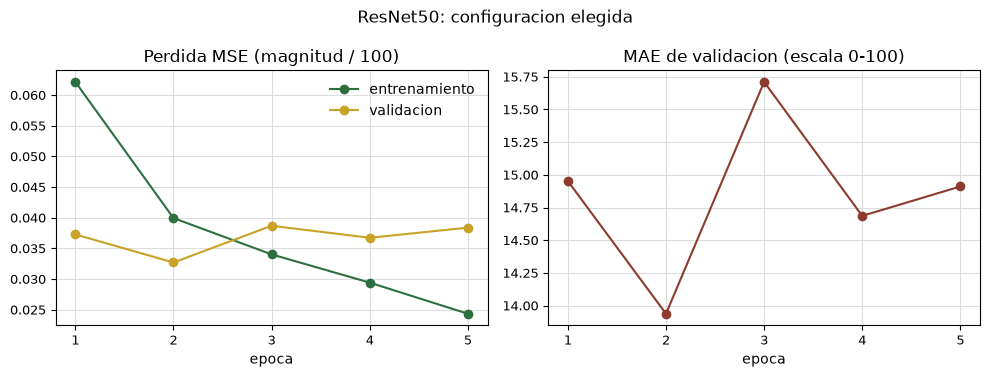

In [5]:
curva = pd.DataFrame([punto.model_dump() for punto in resultados.curva_entrenamiento])
fig, (ax_perdida, ax_mae) = plt.subplots(1, 2, figsize=(10, 3.8))
ax_perdida.plot(curva["epoca"], curva["perdida_entrenamiento"], marker="o", color=PALETA["principal"], label="entrenamiento")
ax_perdida.plot(curva["epoca"], curva["perdida_validacion"], marker="o", color=PALETA["secundario"], label="validacion")
ax_perdida.set_title("Perdida MSE (magnitud / 100)")
ax_perdida.set_xlabel("epoca")
ax_perdida.legend()
ax_mae.plot(curva["epoca"], curva["mae_validacion"], marker="o", color=PALETA["terciario"])
ax_mae.set_title("MAE de validacion (escala 0-100)")
ax_mae.set_xlabel("epoca")
for ax in (ax_perdida, ax_mae):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("ResNet50: configuracion elegida")
fig.tight_layout()
guardar_figura(fig, "06_curva_resnet")
curva.round(4)

## Resultados sobre la prueba

In [6]:
tabla = tabla_predicciones(resultados)
es_sequia = tabla["dano"] == "DR"
pd.DataFrame(
    {"DR": metricas(tabla.loc[es_sequia, "real"], tabla.loc[es_sequia, "predicho"]),
     "global": metricas(tabla["real"], tabla["predicho"])}
).T.round(3)

,n,mae,rmse,r2
DR,834.0,15.028,18.806,0.390
global,4628.0,2.708,7.983,0.816
